# End-to-End Information Retrieval Search Engine
### Crawling, indexing, and ranked search over Ferdowsi University's English website

This project implements a complete classical Information Retrieval (IR) pipeline. It starts by crawling public pages from Ferdowsi University's English website, extracts and stores page content, then builds an index and supports Boolean and ranked retrieval.

**Pipeline:** Web crawling → document collection → text preprocessing → inverted index → TF-IDF → cosine-similarity ranking → evaluation.

The crawler is implemented directly in this notebook. The crawl output is generated locally at runtime, so the GitHub repository does not need to include a pre-generated JSON dataset.

> **Responsible crawling:** The crawler checks the site's `robots.txt`, stays on `en.um.ac.ir`, skips common non-HTML files, and uses a configurable page limit and delay. Review the website's policies before running it.

## 1. Setup and imports


In [18]:
%pip install -q requests beautifulsoup4 lxml nltk pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
import json
import math
import re
import time
from collections import Counter, defaultdict, deque
from pathlib import Path
from urllib.parse import urljoin, urlparse, urldefrag
from urllib.robotparser import RobotFileParser

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# Download the standard list when possible; use a small fallback if offline.
try:
    nltk.download("stopwords", quiet=True)
    ENGLISH_STOP_WORDS = set(stopwords.words("english"))
except LookupError:
    ENGLISH_STOP_WORDS = {
        "a", "an", "and", "are", "as", "at", "be", "been", "but", "by",
        "for", "from", "had", "has", "have", "he", "her", "his", "i", "in",
        "is", "it", "its", "of", "on", "or", "our", "she", "that", "the",
        "their", "them", "there", "these", "they", "this", "those", "to",
        "was", "we", "were", "what", "when", "where", "which", "who", "will",
        "with", "you", "your"
    }
    print("NLTK stopwords corpus unavailable; using the built-in fallback list.")

pd.set_option("display.max_colwidth", 100)

## 2. Load the document collection (optional crawler included)

This project includes the 522-page crawl dataset from the original assignment at `data/crawled_data.json`, so the notebook works without making network requests. The notebook also retains an optional crawler implementation for cases where crawling is permitted. It checks the target site's `robots.txt` and stops if crawling is disallowed; do not bypass that restriction.

By default, `RUN_CRAWLER = False` loads the included dataset.


In [ ]:
# Crawl configuration
START_URL = "https://en.um.ac.ir/"
ALLOWED_HOST = "en.um.ac.ir"
MAX_PAGES = 1000          
REQUEST_DELAY = 1.0      # Seconds between requests.
REQUEST_TIMEOUT = 20
RUN_CRAWLER = False  # Use the included 522-page dataset by default.

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
DATA_PATH = DATA_DIR / "crawled_data.json"

USER_AGENT = "IRCourseSearchEngine/1.0 (educational research; contact: replace-with-your-email)"
SKIP_EXTENSIONS = (
    ".pdf", ".jpg", ".jpeg", ".png", ".gif", ".svg", ".webp",
    ".doc", ".docx", ".xls", ".xlsx", ".ppt", ".pptx", ".zip",
    ".mp4", ".mp3", ".avi", ".mov", ".rar", ".7z"
)

def normalize_page_url(url):
    """Remove fragments and normalize a URL while keeping it on the target host."""
    url, _ = urldefrag(url)
    parsed = urlparse(url)
    if parsed.scheme not in {"http", "https"}:
        return None
    if parsed.netloc.lower() != ALLOWED_HOST:
        return None
    if parsed.path.lower().endswith(SKIP_EXTENSIONS):
        return None
    return f"https://{ALLOWED_HOST}{parsed.path or '/'}"

def load_robots_policy():
    """Read robots.txt; if it cannot be read, stop rather than bypass the policy."""
    parser = RobotFileParser()
    parser.set_url(f"https://{ALLOWED_HOST}/robots.txt")
    parser.read()
    return parser

def extract_page(response):
    """Extract page title, readable text, and same-site links from HTML."""
    soup = BeautifulSoup(response.text, "lxml")
    for element in soup(["script", "style", "header", "footer", "nav", "aside", "noscript"]):
        element.decompose()
    title_tag = soup.find("title")
    title = title_tag.get_text(" ", strip=True) if title_tag else response.url
    main_content = soup.find("main") or soup.find("article") or soup.body or soup
    content = re.sub(r"\s+", " ", main_content.get_text(" ", strip=True)).strip()
    links = []
    for anchor in soup.find_all("a", href=True):
        link = normalize_page_url(urljoin(response.url, anchor["href"]))
        if link:
            links.append(link)
    return title, content, links

def crawl_website(start_url=START_URL, max_pages=MAX_PAGES, delay=REQUEST_DELAY):
    """Breadth-first crawl of allowed pages, respecting robots.txt and request delay."""
    robots = load_robots_policy()
    session = requests.Session()
    session.headers.update({"User-Agent": USER_AGENT})
    start_url = normalize_page_url(start_url)
    if not start_url:
        raise ValueError("START_URL must be an HTTP(S) URL on the allowed university host.")
    if not robots.can_fetch(USER_AGENT, start_url):
        raise RuntimeError(f"robots.txt disallows crawling the start URL: {start_url}")

    queue = deque([start_url])
    discovered = {start_url}
    records, failures = [], 0
    print(f"Starting crawl: {start_url}")
    print(f"Maximum pages: {max_pages} | Request delay: {delay:.1f}s")

    while queue and len(records) < max_pages:
        url = queue.popleft()
        if not robots.can_fetch(USER_AGENT, url):
            continue
        try:
            response = session.get(url, timeout=REQUEST_TIMEOUT)
            response.raise_for_status()
            canonical_url = normalize_page_url(response.url)
            if not canonical_url:
                continue  # Do not index pages redirected outside the allowed host.
            if "text/html" not in response.headers.get("Content-Type", "").lower():
                continue
            title, content, links = extract_page(response)
            if len(content) > 100:
                records.append({"url": canonical_url, "title": title, "content": content})
            for link in links:
                if link not in discovered and robots.can_fetch(USER_AGENT, link):
                    discovered.add(link)
                    queue.append(link)
            if len(records) and len(records) % 10 == 0:
                print(f"Collected {len(records)} pages; queued {len(queue)} more URLs.")
        except requests.RequestException as error:
            failures += 1
            print(f"Skipped {url}: {error}")
        time.sleep(delay)

    session.close()
    if not records:
        raise RuntimeError(
            "The crawl returned no usable pages. Check network access, the website, "
            "and robots.txt. The crawler intentionally does not bypass crawl restrictions."
        )
    with DATA_PATH.open("w", encoding="utf-8") as file:
        json.dump(records, file, ensure_ascii=False, indent=2)
    print("\nCrawl complete.")
    print(f"Pages saved: {len(records):,} | Request failures: {failures:,}")
    print(f"Dataset: {DATA_PATH.resolve()}")
    return records

if RUN_CRAWLER:
    crawled_records = crawl_website()
else:
    if not DATA_PATH.exists():
        raise FileNotFoundError(f"{DATA_PATH} does not exist. Set RUN_CRAWLER = False  # Use the included 522-page dataset by default. to create it.")
    with DATA_PATH.open("r", encoding="utf-8") as file:
        crawled_records = json.load(file)

## 3. Inspect the collected document collection



In [21]:
documents = {}
for record in crawled_records:
    url = record.get("url", "").strip()
    if not url:
        continue
    documents[url] = {
        "url": url,
        "title": record.get("title") or url,
        "content": record.get("content") or "",
    }

print(f"Documents loaded: {len(documents):,}")
display(pd.DataFrame([
    {"title": d["title"], "url": d["url"], "characters": len(d["content"])}
    for d in list(documents.values())[:8]
]))

Documents loaded: 522


,title,url,characters
0,Ferdowsi University of Mashhad: Third University in Iran,https://en.um.ac.ir/content/Laboratory-Network-Management-Office.html,4646
1,Ferdowsi University of Mashhad: Third University in Iran,https://en.um.ac.ir/content/Vice-President-for-Socio-Cultural-and-Student-affairs.html,5418
2,Ferdowsi University of Mashhad: Third University in Iran,https://en.um.ac.ir/content/Educational-Planning-and-Academic-Development-Office.html,2801
3,Ferdowsi University of Mashhad: Third University in Iran,https://en.um.ac.ir/content/College-of-Ferdowsi-University-of-Mashhad.html,4315
4,Ferdowsi University of Mashhad: Third University in Iran,https://en.um.ac.ir/content/E-Learning-Center.html,4350
5,Commencement of the master plan for developing technologies to improve subsurface imaging in the...,https://en.um.ac.ir/News-2946.html,2213
6,Commencement of the master plan for developing technologies to improve subsurface imaging in the...,https://en.um.ac.ir/modulesbb89.html?op=modload&name=News&file=article&sid=2946,2213
7,Joint meeting of the President of Ferdowsi University of Mashhad with Rear Admiral Habibollah Sa...,https://en.um.ac.ir/News-2947.html,1243


In [22]:
corpus_stats = pd.Series({
    "Number of documents": len(documents),
    "Documents with non-empty content": sum(bool(d["content"].strip()) for d in documents.values()),
    "Total characters": sum(len(d["content"]) for d in documents.values()),
    "Average characters per document": round(
        sum(len(d["content"]) for d in documents.values()) / max(len(documents), 1), 1
    ),
})
display(corpus_stats.to_frame("Value"))

,Value
Number of documents,522.0
Documents with non-empty content,522.0
Total characters,3285634.0
Average characters per document,6294.3


## 4. Text preprocessing

The preprocessing pipeline:

1. Converts text to lowercase.
2. Removes HTML fragments and non-alphabetic characters.
3. Tokenizes into words.
4. Removes English stopwords and very short tokens.
5. Applies Porter stemming to normalize related word forms.

The same preprocessing function is applied to documents and queries to keep their term representations consistent.

In [23]:
class TextPreprocessor:
    def __init__(self):
        self.stop_words = ENGLISH_STOP_WORDS
        self.stemmer = PorterStemmer()

    def preprocess(self, text):
        text = re.sub(r"<[^>]+>", " ", str(text).lower())
        text = re.sub(r"[^a-z\s]", " ", text)
        tokens = re.findall(r"[a-z]+", text)
        tokens = [token for token in tokens
                  if token not in self.stop_words and len(token) > 2]
        return [self.stemmer.stem(token) for token in tokens]

preprocessor = TextPreprocessor()
processed_documents = {}

for doc_id, document in documents.items():
    tokens = preprocessor.preprocess(document["title"] + " " + document["content"])
    processed_documents[doc_id] = {**document, "tokens": tokens}

print(f"Processed documents: {len(processed_documents):,}")
print("Example tokens:", next(iter(processed_documents.values()))["tokens"][:30])

Processed documents: 522
Example tokens: ['ferdowsi', 'univers', 'mashhad', 'third', 'univers', 'iran', 'ferdowsi', 'univers', 'mashhad', 'third', 'univers', 'iran', 'fum', 'offici', 'fum', 'presid', 'word', 'presid', 'vice', 'presid', 'vice', 'presid', 'academ', 'affair', 'colleg', 'ferdowsi', 'univers', 'mashhad', 'educ', 'plan']


## 5. Build an inverted index



In [24]:
inverted_index = defaultdict(set)
document_frequency = Counter()
document_term_counts = {}

for doc_id, document in processed_documents.items():
    term_counts = Counter(document["tokens"])
    document_term_counts[doc_id] = term_counts
    for term in term_counts:
        inverted_index[term].add(doc_id)
        document_frequency[term] += 1

N = len(processed_documents)
vocabulary = set(inverted_index)
number_of_postings = sum(len(postings) for postings in inverted_index.values())

print(f"Documents: {N:,}")
print(f"Vocabulary size: {len(vocabulary):,}")
print(f"Total postings: {number_of_postings:,}")
print(f"Average unique terms per document: {sum(map(len, document_term_counts.values())) / max(N, 1):.1f}")

Documents: 522
Vocabulary size: 10,957
Total postings: 111,962
Average unique terms per document: 214.5


In [25]:
# Inspect a few terms with the largest posting lists.
most_common_terms = sorted(
    inverted_index.items(), key=lambda item: len(item[1]), reverse=True
)[:15]
display(pd.DataFrame([
    {"term": term, "document_frequency": len(postings),
     "sample_document_ids": list(sorted(postings))[:3]}
    for term, postings in most_common_terms
]))

,term,document_frequency,sample_document_ids
0,ferdowsi,518,"[http://en.um.ac.ir/, http://en.um.ac.ir/AddStory-ListArchive-act-search.html, http://en.um.ac.i..."
1,univers,518,"[http://en.um.ac.ir/, http://en.um.ac.ir/AddStory-ListArchive-act-search.html, http://en.um.ac.i..."
2,mashhad,518,"[http://en.um.ac.ir/, http://en.um.ac.ir/AddStory-ListArchive-act-search.html, http://en.um.ac.i..."
3,third,512,"[http://en.um.ac.ir/, http://en.um.ac.ir/AddStory-ListArchive-act-search.html, http://en.um.ac.i..."
4,iran,512,"[http://en.um.ac.ir/, http://en.um.ac.ir/AddStory-ListArchive-act-search.html, http://en.um.ac.i..."
5,center,414,"[http://en.um.ac.ir/News-2945.html, http://en.um.ac.ir/News-2946.html, http://en.um.ac.ir/News.h..."
6,top,404,"[http://en.um.ac.ir/AddStory-ListArchive-act-search.html, http://en.um.ac.ir/content/22-Bahman-S..."
7,inform,386,"[http://en.um.ac.ir/content/A-word-from-the-President.html, http://en.um.ac.ir/content/About.htm..."
8,academ,384,"[http://en.um.ac.ir/content/22-Bahman-Sport-Complex.html, http://en.um.ac.ir/content/A-word-from..."
9,human,372,"[http://en.um.ac.ir/, http://en.um.ac.ir/News.html, http://en.um.ac.ir/Topic26.html]"


## 6. Boolean retrieval (AND)

Boolean AND retrieval returns only documents that contain **every** query term. This is a useful exact-match baseline alongside ranked retrieval.

In [26]:
def boolean_and_search(query, top_k=20):
    terms = list(dict.fromkeys(preprocessor.preprocess(query)))
    if not terms:
        return []

    # Start with the smallest posting list to reduce intersection work.
    posting_lists = [inverted_index.get(term, set()) for term in terms]
    if any(not postings for postings in posting_lists):
        return []

    posting_lists.sort(key=len)
    matches = set(posting_lists[0])
    for postings in posting_lists[1:]:
        matches.intersection_update(postings)
        if not matches:
            break

    return sorted(matches)[:top_k]

boolean_query = "research centers"
boolean_results = boolean_and_search(boolean_query)
print(f"Query: {boolean_query!r}")
print(f"Matching documents: {len(boolean_results)}")
for url in boolean_results[:5]:
    print("-", processed_documents[url]["title"], "|", url)

Query: 'research centers'
Matching documents: 20
- Commencement of the master plan for developing technologies to improve subsurface imaging in the exploration of hydrocarbon resources in the Kopeh Dagh sedimentary basin at Ferdowsi University of Mash :: Ferdowsi University of Mashhad :: Ferdowsi University of Mashhad: Third University in Iran | http://en.um.ac.ir/News-2946.html
- Ferdowsi University of Mashhad: Third University in Iran | http://en.um.ac.ir/News.html
- Ferdowsi University of Mashhad: Third University in Iran | http://en.um.ac.ir/content/A-word-from-the-President.html
- Ferdowsi University of Mashhad: Third University in Iran | http://en.um.ac.ir/content/About.html
- Ferdowsi University of Mashhad: Third University in Iran | http://en.um.ac.ir/content/Air-and-Solar-Research-Institute.html


## 7. TF-IDF document representation




In [27]:
# Calculate IDF once for the collection.
idf = {
    term: math.log(N / df)
    for term, df in document_frequency.items()
    if df > 0 and N > 0
}

def normalized_tf(tokens):
    counts = Counter(tokens)
    total = len(tokens)
    if total == 0:
        return {}
    return {term: count / total for term, count in counts.items()}

def l2_normalize(vector):
    norm = math.sqrt(sum(weight * weight for weight in vector.values()))
    if norm == 0:
        return {}
    return {term: weight / norm for term, weight in vector.items()}

document_vectors = {}
for doc_id, document in processed_documents.items():
    tf = normalized_tf(document["tokens"])
    tfidf = {term: tf_value * idf.get(term, 0.0)
             for term, tf_value in tf.items() if idf.get(term, 0.0) > 0}
    document_vectors[doc_id] = l2_normalize(tfidf)

print(f"TF-IDF vectors created: {len(document_vectors):,}")
print("Example vector:", list(next(iter(document_vectors.values())).items())[:10])

TF-IDF vectors created: 522
Example vector: [('ferdowsi', 0.0004095559342018094), ('univers', 0.0008191118684036188), ('mashhad', 0.0005733783078825332), ('third', 0.00041194328001083815), ('iran', 0.0008238865600216763), ('fum', 0.06164365967908079), ('offici', 0.031310046177259486), ('presid', 0.11453051450328963), ('word', 0.015833992037257983), ('vice', 0.08784073200102677)]


## 8. Ranked retrieval with cosine similarity



In [28]:
def create_query_vector(query):
    tokens = preprocessor.preprocess(query)
    tf = normalized_tf(tokens)
    query_tfidf = {
        term: tf_value * idf[term]
        for term, tf_value in tf.items()
        if term in idf and idf[term] > 0
    }
    return l2_normalize(query_tfidf)

def search(query, top_k=10):
    start = time.perf_counter()
    query_vector = create_query_vector(query)
    if not query_vector:
        elapsed_ms = (time.perf_counter() - start) * 1000
        return [], elapsed_ms

    # Accumulate scores only for documents that contain query terms.
    scores = defaultdict(float)
    for term, query_weight in query_vector.items():
        for doc_id in inverted_index.get(term, ()):
            scores[doc_id] += query_weight * document_vectors[doc_id].get(term, 0.0)

    ranked = sorted(scores.items(), key=lambda item: item[1], reverse=True)[:top_k]
    results = [
        {"title": processed_documents[doc_id]["title"],
         "url": doc_id, "score": score}
        for doc_id, score in ranked if score > 0
    ]
    elapsed_ms = (time.perf_counter() - start) * 1000
    return results, elapsed_ms

def display_results(query, results, elapsed_ms):
    print(f"Query: {query}")
    print(f"Search time: {elapsed_ms:.3f} ms | Results: {len(results)}")
    if not results:
        print("No matching documents. Try different or broader terms.")
        return
    for rank, result in enumerate(results, start=1):
        print(f"\n{rank}. {result['title']}")
        print(f"   Cosine similarity: {result['score']:.4f}")
        print(f"   {result['url']}")

In [29]:
# Try changing this query to explore the collection.
query = "computer engineering faculty members"
results, elapsed_ms = search(query, top_k=10)
display_results(query, results, elapsed_ms)

Query: computer engineering faculty members
Search time: 1.502 ms | Results: 10

1. Ferdowsi University of Mashhad: Third University in Iran
   Cosine similarity: 0.3269
   https://en.um.ac.ir/content/Faculty-of-Engineering.html

2. Ferdowsi University of Mashhad: Third University in Iran
   Cosine similarity: 0.3269
   http://en.um.ac.ir/content/Faculty-of-Engineering.html

3. Ferdowsi University of Mashhad: Third University in Iran
   Cosine similarity: 0.2644
   http://en.um.ac.ir/content/test-prof.html

4. Ferdowsi University of Mashhad: Third University in Iran
   Cosine similarity: 0.2644
   https://en.um.ac.ir/content/test-prof.html

5. Ferdowsi University of Mashhad: Third University in Iran
   Cosine similarity: 0.2551
   http://en.um.ac.ir/content/Faculty-of-Science.html

6. Ferdowsi University of Mashhad: Third University in Iran
   Cosine similarity: 0.2551
   https://en.um.ac.ir/content/Faculty-of-Science.html

7. Ferdowsi University of Mashhad: Third University in Iran
  

## 9. Run a small query set and inspect performance



In [30]:
sample_queries = [
    "computer engineering faculty members",
    "international students admission",
    "research centers and laboratories",
    "graduate programs in science",
    "campus facilities and libraries",
]

query_measurements = []
for query in sample_queries:
    results, elapsed_ms = search(query, top_k=5)
    query_measurements.append({
        "query": query,
        "results_returned": len(results),
        "latency_ms": elapsed_ms,
        "top_result": results[0]["title"] if results else "No result",
    })

performance_df = pd.DataFrame(query_measurements)
display(performance_df)
print(f"Average query latency: {performance_df['latency_ms'].mean():.3f} ms")

,query,results_returned,latency_ms,top_result
0,computer engineering faculty members,5,1.4858,Ferdowsi University of Mashhad: Third University in Iran
1,international students admission,5,1.3607,Ferdowsi University of Mashhad: Third University in Iran
2,research centers and laboratories,5,1.3935,Ferdowsi University of Mashhad: Third University in Iran
3,graduate programs in science,5,1.0011,Ferdowsi University of Mashhad: Third University in Iran
4,campus facilities and libraries,5,0.7656,Ferdowsi University of Mashhad: Third University in Iran


Average query latency: 1.201 ms


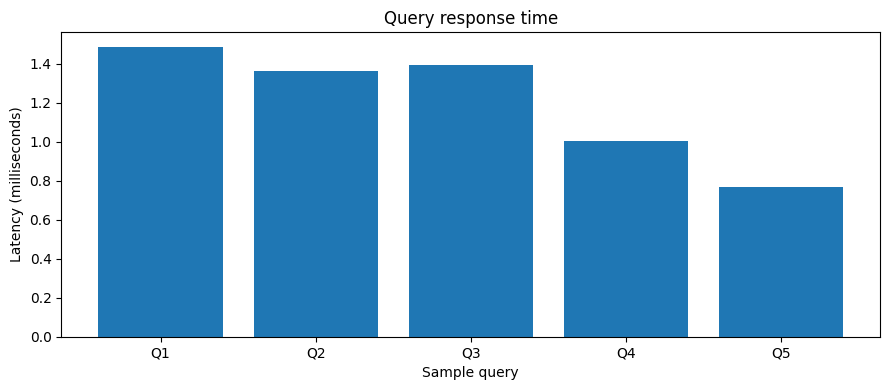

In [31]:
plt.figure(figsize=(9, 4))
plt.bar(range(len(performance_df)), performance_df["latency_ms"])
plt.xticks(range(len(performance_df)), [f"Q{i+1}" for i in range(len(performance_df))])
plt.xlabel("Sample query")
plt.ylabel("Latency (milliseconds)")
plt.title("Query response time")
plt.tight_layout()
plt.show()

## 10. Retrieval evaluation helpers



In [32]:
def precision_at_k(retrieved_ids, relevant_ids, k=10):
    retrieved = retrieved_ids[:k]
    if not retrieved:
        return 0.0
    relevant = set(relevant_ids)
    return sum(doc_id in relevant for doc_id in retrieved) / len(retrieved)

def recall_at_k(retrieved_ids, relevant_ids, k=10):
    relevant = set(relevant_ids)
    if not relevant:
        return 0.0
    return sum(doc_id in relevant for doc_id in retrieved_ids[:k]) / len(relevant)

def f1_at_k(retrieved_ids, relevant_ids, k=10):
    precision = precision_at_k(retrieved_ids, relevant_ids, k)
    recall = recall_at_k(retrieved_ids, relevant_ids, k)
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0

# Example only: replace these URLs with documents judged relevant by a human.
# judged_relevant_urls = {"https://en.um.ac.ir/...", "https://en.um.ac.ir/..."}
# retrieved_urls = [item["url"] for item in search("research laboratories", 10)[0]]
# print("P@10:", precision_at_k(retrieved_urls, judged_relevant_urls, 10))
# print("R@10:", recall_at_k(retrieved_urls, judged_relevant_urls, 10))
# print("F1@10:", f1_at_k(retrieved_urls, judged_relevant_urls, 10))

## 11. Final system summary

In [33]:
summary = {
    "Documents indexed": N,
    "Vocabulary size": len(vocabulary),
    "Total postings": number_of_postings,
    "Average unique terms per document": round(
        sum(len(counts) for counts in document_term_counts.values()) / max(N, 1), 2
    ),
    "Average sample-query latency (ms)": round(performance_df["latency_ms"].mean(), 3),
}
display(pd.Series(summary, name="Value").to_frame())

,Value
Documents indexed,522.000
Vocabulary size,10957.000
Total postings,111962.000
Average unique terms per document,214.490
Average sample-query latency (ms),1.201
